# 02 — Quasi-steady-state (QSS) lap-time simulation on ovals

A point-mass QSS lap simulation with **banking**, **aero downforce/drag**, **power limit** and a **friction ellipse with load sensitivity**. It is deliberately simple. The point is to show *how the problem changes* between oval types compared with a road course:

| Track type | What limits the lap | Typical NASCAR package |
|---|---|---|
| Superspeedway (Daytona/Talladega) | drag & power: flat out, solo | tapered spacer ~510 hp, low drag |
| Intermediate 1.5 mi (Charlotte, Vegas…) | right at the edge of grip vs. power | 670 hp, more downforce |
| Short track (Martinsville…) | braking, traction, mechanical grip | 750 hp from 2026 |

The parameters are rough and calibrated only to give plausible lap times (Charlotte-like ≈ 30–31 s, Martinsville-like ≈ 20 s, Daytona-like ≈ 49 s solo). Track geometry is simplified to straights plus constant-radius turns with smoothed transitions.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': 0.3})
RHO, G, MPH, HP = 1.18, 9.81, 2.23694, 745.7

def make_oval(L_straight, R, bank_turn_deg, bank_straight_deg=5.0, ds=2.0, smooth=60.0):
    segs = [(L_straight, 0.0, bank_straight_deg), (np.pi*R, 1/R, bank_turn_deg),
            (L_straight, 0.0, bank_straight_deg), (np.pi*R, 1/R, bank_turn_deg)]
    k, th = [], []
    for L, kap, b in segs:
        n = int(round(L/ds)); k += [kap]*n; th += [np.deg2rad(b)]*n
    k, th = np.array(k), np.array(th)
    w = int(smooth/ds); ker = np.ones(w)/w           # crude spiral / banking transitions
    sm = lambda x: np.convolve(np.r_[x[-w:], x, x[:w]], ker, 'same')[w:-w]
    return dict(s=np.arange(len(k))*ds, kap=sm(k), th=sm(th), ds=ds)

def car(**kw):
    c = dict(m=1600., P=670*HP, eta=0.88, CdA=1.10, ClA=1.6, mu0=1.0,
             load_sens=0.12, Fz0=4000., Crr=0.012)
    c.update(kw); return c

def loads(c, v, kap, th):
    N  = c['m']*(G*np.cos(th) + v**2*kap*np.sin(th)) + 0.5*RHO*c['ClA']*v**2
    Fy = c['m']*(v**2*kap*np.cos(th) - G*np.sin(th))
    return N, Fy

def mu_eff(c, N):
    return c['mu0']*(N/4/c['Fz0'])**(-c['load_sens'])

def resist(c, v):
    return 0.5*RHO*c['CdA']*v**2 + c['Crr']*c['m']*G

def v_corner(c, kap, th, vcap=110.):
    # steady-state limit: lateral force AND the drive force needed to hold speed must fit in the friction ellipse
    if kap < 1e-7: return vcap
    lo, hi = 1., vcap
    for _ in range(50):
        v = 0.5*(lo+hi); N, Fy = loads(c, v, kap, th); F = mu_eff(c, N)*N
        lo, hi = (v, hi) if (Fy/F)**2 + (resist(c, v)/F)**2 <= 1 else (lo, v)
    return lo

def fx_grip(c, v, kap, th):
    N, Fy = loads(c, v, kap, th); F = mu_eff(c, N)*N
    return F*np.sqrt(max(0., 1-(Fy/F)**2))

def lapsim(c, tr, laps=3):
    # forward (traction/power) and backward (braking) passes, repeated over several laps so the
    # periodic solution is reached even when the car never touches a grip limit (superspeedway)
    kap, th, ds = tr['kap'], tr['th'], tr['ds']; n = len(kap)
    vl = np.array([v_corner(c, kap[i], th[i]) for i in range(n)])
    vf = np.empty(n); lim = np.zeros(n, int)            # 0 grip, 1 power/drag, 2 braking
    v = min(vl.min(), 60.)
    for _ in range(laps):                               # forward pass
        for i in range(n):
            p = i-1
            fg, fp = fx_grip(c, v, kap[p], th[p]), c['eta']*c['P']/max(v, 1.)
            a = (min(fg, fp) - resist(c, v))/c['m']
            va = np.sqrt(max(v**2 + 2*a*ds, 1.))
            if va >= vl[i] - 1e-3: v, lim[i] = vl[i], 0
            else: v, lim[i] = va, 1
            vf[i] = v
    vb = vf.copy(); v = vf[-1]
    for _ in range(laps):                               # backward pass
        for i in range(n-1, -1, -1):
            nx = (i+1) % n
            a = (fx_grip(c, v, kap[nx], th[nx]) + resist(c, v))/c['m']
            vbr = np.sqrt(v**2 + 2*a*ds)
            if vbr < vf[i]: v = vbr; vb[i] = v; lim[i] = 2
            else: v = vf[i]; vb[i] = v
    return dict(t=np.sum(ds/vb), v=vb, vlim=vl, lim=lim)

TRACKS = {
  'Superspeedway (2.5 mi, 31°)':  (make_oval(1050, 306, 31, 3), car(P=510*HP, CdA=0.98, ClA=0.9)),
  'Intermediate (1.5 mi, 24°)':   (make_oval(530, 215, 24),     car()),
  'Short track (0.526 mi, 12°)':  (make_oval((846.5-2*np.pi*65)/2, 65, 12, 0), car(P=750*HP, CdA=1.0, ClA=1.2, mu0=1.3)),
}
RES = {k: lapsim(c, tr) for k, (tr, c) in TRACKS.items()}
for k, r in RES.items():
    L = TRACKS[k][0]['s'][-1] + TRACKS[k][0]['ds']
    frac = [np.mean(r['lim'] == q)*100 for q in (0, 1, 2)]
    print(f"{k:30s} lap {r['t']:6.2f} s | avg {L/r['t']*MPH:5.1f} mph | min/max {r['v'].min()*MPH:5.1f}/{r['v'].max()*MPH:5.1f} mph"
          f" | grip {frac[0]:4.1f}%  power {frac[1]:4.1f}%  brake {frac[2]:4.1f}%")

Superspeedway (2.5 mi, 31°)    lap  49.05 s | avg 183.5 mph | min/max 183.5/183.5 mph | grip  0.0%  power 100.0%  brake  0.0%
Intermediate (1.5 mi, 24°)     lap  30.79 s | avg 175.2 mph | min/max 172.2/183.6 mph | grip 51.2%  power 45.6%  brake  3.2%
Short track (0.526 mi, 12°)    lap  19.92 s | avg  95.2 mph | min/max  81.5/128.7 mph | grip 34.4%  power 45.3%  brake 20.3%


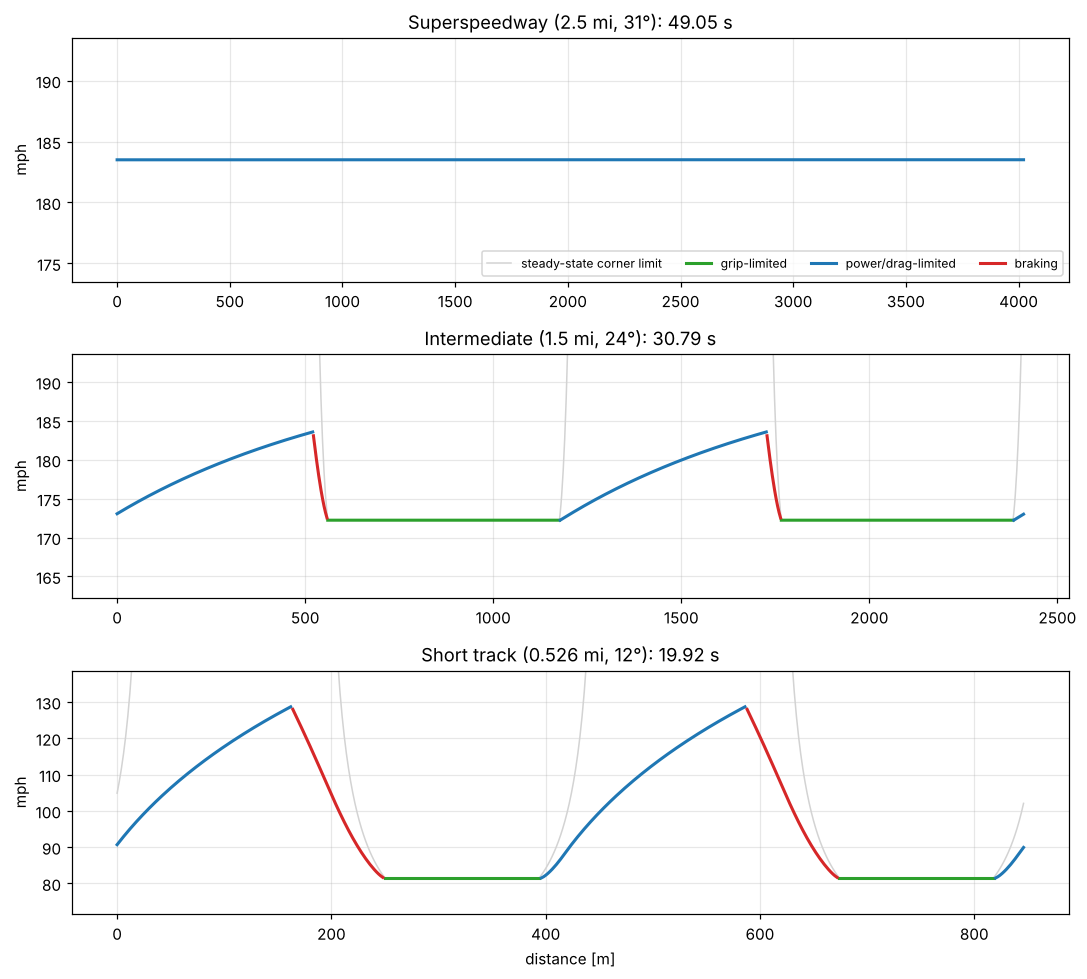

In [2]:
fig, axs = plt.subplots(3, 1, figsize=(10, 9))
cols = {0: 'tab:green', 1: 'tab:blue', 2: 'tab:red'}
for ax, (k, r) in zip(axs, RES.items()):
    s = TRACKS[k][0]['s']
    ax.plot(s, r['vlim']*MPH, c='lightgrey', lw=1, label='steady-state corner limit')
    for q, lab in [(0, 'grip-limited'), (1, 'power/drag-limited'), (2, 'braking')]:
        m = np.where(r['lim'] == q, r['v']*MPH, np.nan); ax.plot(s, m, c=cols[q], lw=2, label=lab)
    lo, hi = np.nanmin(r['v'])*MPH, np.nanmax(r['v'])*MPH
    ax.set(ylim=(lo-10, hi+10), ylabel='mph', title=f"{k}: {r['t']:.2f} s")
axs[0].legend(fontsize=8, ncol=4, loc='lower right'); axs[-1].set_xlabel('distance [m]')
plt.tight_layout(); plt.show()

**Reading the traces**
* **Superspeedway:** speed barely changes around the lap. The car is never grip-limited solo; the lap time is set by $P\eta = \tfrac12\rho C_DA v^3 + F_{roll}v$. Setup goes into **drag** (ride height in the draft, skew, body-panel tolerances) and **handling in traffic**. The car has to stay drivable in dirty air at 3-wide.
* **Intermediate:** a large share of the lap sits on the grip boundary but with only a small speed dip. The lap is set by **mid-corner grip** (mechanical + aero) and how early the driver can get to full throttle. Small balance changes are worth tenths. This is the most "classic vehicle dynamics" oval.
* **Short track:** braking and traction phases dominate, similar to a slow road course with two identical corners. With 750 hp (2026) traction management and tyre falloff become more important.

## Sensitivities: what is a tenth worth?
A lap-time engineer's most useful output is the **sensitivity table**. The same perturbations, applied to three different tracks, give very different priorities. That is the core reason a NASCAR performance group runs track-type-specific models and packages.

In [3]:
perturb = {
    'CdA −5 %':       lambda c: c.update(CdA=c['CdA']*0.95),
    'ClA +5 %':       lambda c: c.update(ClA=c['ClA']*1.05),
    'μ0 +2 %':        lambda c: c.update(mu0=c['mu0']*1.02),
    'Power +10 hp':   lambda c: c.update(P=c['P']+10*HP),
    'Mass −20 kg':    lambda c: c.update(m=c['m']-20),
    'Load sens. −20 %': lambda c: c.update(load_sens=c['load_sens']*0.8),
}
print(f"{'Δ lap time [s]':18s}" + ''.join(f'{k.split(" (")[0]:>16s}' for k in TRACKS))
for name, f in perturb.items():
    row = []
    for k, (tr, c0) in TRACKS.items():
        c = dict(c0); f(c); row.append(lapsim(c, tr)['t'] - RES[k]['t'])
    print(f'{name:18s}' + ''.join(f'{d:16.3f}' for d in row))

Δ lap time [s]       Superspeedway    Intermediate     Short track


CdA −5 %                    -0.818          -0.070          -0.007


ClA +5 %                     0.000          -0.134          -0.019


μ0 +2 %                      0.000          -0.408          -0.195


Power +10 hp                -0.326          -0.023          -0.016


Mass −20 kg                 -0.010          -0.067          -0.033


Load sens. −20 %             0.000          -0.436          -0.079


Typical pattern (exact numbers depend on calibration):
* Superspeedway: **drag and power only**. Grip and downforce are worth ~0 solo. In the pack, the draft changes everything (next cell).
* Intermediate: **grip/downforce dominate**, drag still matters. This is a genuine trade-off, which is why the spoiler/package size is NASCAR's main lever on the racing at these tracks.
* Short track: grip, mass and braking. Aero is almost irrelevant.

Compared with a typical road course (or F1/GT), the oval problem is **narrow**: very few, very long corners, all in the same direction. Every 0.1 % of mid-corner grip is used for most of the lap, with no braking or traction phases to dilute it.

## Drafting on a superspeedway
In a two-car draft the trailing car loses a large share of drag (wake), and the lead car also gains a little because its base pressure recovers. Numbers below are generic and illustrative (Romberg et al., SAE 710213 measured this first in 1971): trailing ≈ −25–35 % drag, lead ≈ −5–10 %.

In [4]:
tr, c0 = TRACKS['Superspeedway (2.5 mi, 31°)']
solo = RES['Superspeedway (2.5 mi, 31°)']['t']
L = tr['s'][-1] + tr['ds']
print(f'solo                : {solo:6.2f} s  ({L/solo*MPH:5.1f} mph)')
for lead_red, trail_red in [(0.05, 0.25), (0.08, 0.30)]:
    # in a stable two-car draft both cars must run the same speed -> they share an average drag reduction
    cpair = dict(c0); cpair['CdA'] = c0['CdA']*(1 - 0.5*(lead_red+trail_red))
    ctrail = dict(c0); ctrail['CdA'] = c0['CdA']*(1 - trail_red)
    t_pair, t_trail = lapsim(cpair, tr)['t'], lapsim(ctrail, tr)['t']
    print(f'draft lead −{lead_red:.0%}/trail −{trail_red:.0%}: tandem pair {t_pair:6.2f} s ({L/t_pair*MPH:5.1f} mph) | '
          f'trailing car "would-be" pace {t_trail:6.2f} s → closing-speed potential '
          f'{(L/t_trail - L/solo)*MPH:4.1f} mph')

solo                :  49.05 s  (183.5 mph)


draft lead −5%/trail −25%: tandem pair  46.51 s (193.5 mph) | trailing car "would-be" pace  44.64 s → closing-speed potential 18.1 mph


draft lead −8%/trail −30%: tandem pair  45.78 s (196.6 mph) | trailing car "would-be" pace  43.65 s → closing-speed potential 22.7 mph


That closing-speed surplus is the "run" the trailing car uses to pull out and pass. Its size depends on lateral spacing, yaw and side-draft, so this is no longer vehicle dynamics in the classic sense. It is **multi-car aerodynamics**, simulated with multi-body CFD and wake-generator wind-tunnel methods (e.g. Dominy & LeGood, SAE 2008-01-2990) and studied in the DiL simulator with AI traffic.

### Where to go from here
* Replace the point mass with a **4-wheel QSS / g-g-v model**: the g-g-v diagram is cheap to compute and the oval only needs a small slice of it.
* Add **aero maps** $C_L, C_D, \text{balance} = f(\text{RH}_f, \text{RH}_r, \text{yaw}, \text{roll}, \text{steer})$. On ovals the car runs sustained sideslip and several degrees of yaw, so the yaw sensitivity matters more than on road courses.
* Add **tyre wear / temperature** and run 30–60 lap stints: Cup races are decided by long-run falloff, not single-lap pace.